In [1]:
import numpy as np
import pandas as pd

In [2]:
train = pd.read_csv('train_preprocessed.csv', low_memory=False)
test = pd.read_csv('test_preprocessed.csv', low_memory=False)

print('Train Shape:', train.shape)
print('Test Shape:', test.shape)

Train Shape: (1017209, 32)
Test Shape: (41088, 31)


In [3]:
print("Train columns:")
print(train.columns.tolist())

print("\nTest columns:")
print(test.columns.tolist())

print("\nSales available in train:", "Sales" in train.columns)
print("Customers available in train:", "Customers" in train.columns)
print("Sales available in test:", "Sales" in test.columns)
print("Customers available in test:", "Customers" in test.columns)

Train columns:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDistance_was_missing', 'CompetitionOpenSinceMonth_was_missing', 'CompetitionOpenSinceYear_was_missing', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'MonthPeriod', 'MonthSin', 'MonthCos', 'DayOfWeekSin', 'DayOfWeekCos', 'Open_was_missing']

Test columns:
['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'Open_was_missing', 'CompetitionDistance_was_missing', 'CompetitionOpenSinceMonth_was_missing', 'CompetitionOpenSinceYear_was_missing', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsW

In [4]:
print("Sales percentiles:")
print(train["Sales"].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
))

Q1 = train["Sales"].quantile(0.25)
Q3 = train["Sales"].quantile(0.75)

IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

print("\nIQR upper limit:", upper_limit)
print("Potential upper outliers:", (train["Sales"] > upper_limit).sum())

Sales percentiles:
0.250     3727.000
0.500     5744.000
0.750     7856.000
0.900    10288.000
0.950    12137.000
0.990    17160.000
0.999    23979.792
Name: Sales, dtype: float64

IQR upper limit: 14049.5
Potential upper outliers: 26694


In [5]:
sales_outliers = train[train["Sales"] > upper_limit]

print("Outlier rows:", len(sales_outliers))

print("\nAverage Sales:", sales_outliers["Sales"].mean())

print("\nOpen distribution:")
print(sales_outliers["Open"].value_counts())

print("\nPromo distribution:")
print(sales_outliers["Promo"].value_counts())

print("\nStateHoliday distribution:")
print(sales_outliers["StateHoliday"].value_counts())

print("\nMonthly distribution:")
print(sales_outliers["Month"].value_counts().sort_index())

Outlier rows: 26694

Average Sales: 17212.576309282984

Open distribution:
Open
1    26694
Name: count, dtype: int64

Promo distribution:
Promo
1    19187
0     7507
Name: count, dtype: int64

StateHoliday distribution:
StateHoliday
0    26553
a       95
b       35
c       11
Name: count, dtype: int64

Monthly distribution:
Month
1     1927
2     1819
3     2827
4     2666
5     2287
6     2725
7     2396
8     1326
9     1270
10    1154
11    1580
12    4717
Name: count, dtype: int64


In [6]:
Q1_c = train["Customers"].quantile(0.25)
Q3_c = train["Customers"].quantile(0.75)

IQR_c = Q3_c - Q1_c
upper_limit_c = Q3_c + 1.5 * IQR_c

customer_outliers = train[train["Customers"] > upper_limit_c]

print("Customers IQR upper limit:", upper_limit_c)
print("Potential customer outliers:", len(customer_outliers))
print("\nCustomers outlier summary:")
print(customer_outliers["Customers"].describe())

Customers IQR upper limit: 1485.0
Potential customer outliers: 38095

Customers outlier summary:
count    38095.000000
mean      2072.174432
std        606.872375
min       1486.000000
25%       1624.000000
50%       1845.000000
75%       2319.000000
max       7388.000000
Name: Customers, dtype: float64


In [7]:
print("Open = 1 and Sales = 0:",
      ((train["Open"] == 1) & (train["Sales"] == 0)).sum())

print("Open = 0 and Sales > 0:",
      ((train["Open"] == 0) & (train["Sales"] > 0)).sum())

print("Open = 0 and Sales = 0:",
      ((train["Open"] == 0) & (train["Sales"] == 0)).sum())

Open = 1 and Sales = 0: 54
Open = 0 and Sales > 0: 0
Open = 0 and Sales = 0: 172817


In [8]:
zero_sales_open = train[
    (train["Open"] == 1) &
    (train["Sales"] == 0)
]

print("Number of records:", len(zero_sales_open))

print("\nRecords:")
print(
    zero_sales_open[
        ["Store", "Date", "DayOfWeek", "Sales",
         "Customers", "Promo", "StateHoliday"]
    ].to_string(index=False)
)

print("\nCustomers summary:")
print(zero_sales_open["Customers"].describe())

Number of records: 54

Records:
 Store       Date  DayOfWeek  Sales  Customers  Promo StateHoliday
   971 2015-05-15          5      0          0      0            0
   674 2015-03-26          4      0          0      0            0
   699 2015-02-05          4      0          0      1            0
   708 2014-10-01          3      0          0      1            0
   357 2014-09-22          1      0          0      0            0
   227 2014-09-11          4      0          0      0            0
   835 2014-09-11          4      0          0      0            0
   835 2014-09-10          3      0          0      0            0
   548 2014-09-05          5      0          0      1            0
    28 2014-09-04          4      0          0      1            0
    28 2014-09-03          3      0          0      1            0
    28 2014-09-02          2      0          0      1            0
   102 2014-07-24          4      0          0      0            0
   238 2014-07-24          4  

In [9]:
print("Duplicate Store-Date records:",
      train.duplicated(subset=["Store", "Date"]).sum())

print("Duplicate rows in entire train dataset:",
      train.duplicated().sum())

Duplicate Store-Date records: 0
Duplicate rows in entire train dataset: 0


In [10]:
print("Sales minimum:", train["Sales"].min())
print("Sales maximum:", train["Sales"].max())
print("Sales mean:", train["Sales"].mean())
print("Sales standard deviation:", train["Sales"].std())

print("\nZero sales percentage:",
      (train["Sales"].eq(0).mean() * 100))

Sales minimum: 0
Sales maximum: 41551
Sales mean: 5773.818972305593
Sales standard deviation: 3849.926175241448

Zero sales percentage: 16.994639253093514


In [11]:
train["Date"] = pd.to_datetime(train["Date"])

print("Minimum date:", train["Date"].min())
print("Maximum date:", train["Date"].max())

print("\nIs data sorted by date?")
print(train["Date"].is_monotonic_increasing)

print("\nUnique dates:", train["Date"].nunique())

Minimum date: 2013-01-01 00:00:00
Maximum date: 2015-07-31 00:00:00

Is data sorted by date?
False

Unique dates: 942


In [12]:
train = train.sort_values(
    by=["Date", "Store"]
).reset_index(drop=True)

print("Is data sorted by date:",
      train["Date"].is_monotonic_increasing)

print("\nFirst 5 records:")
print(train[["Date", "Store", "Sales"]].head())

print("\nLast 5 records:")
print(train[["Date", "Store", "Sales"]].tail())

Is data sorted by date: True

First 5 records:
        Date  Store  Sales
0 2013-01-01      1      0
1 2013-01-01      2      0
2 2013-01-01      3      0
3 2013-01-01      4      0
4 2013-01-01      5      0

Last 5 records:
              Date  Store  Sales
1017204 2015-07-31   1111   5723
1017205 2015-07-31   1112   9626
1017206 2015-07-31   1113   7289
1017207 2015-07-31   1114  27508
1017208 2015-07-31   1115   8680


In [13]:
# Chronological train-validation split

split_date = "2015-06-01"

train_data = train[train["Date"] < split_date].copy()

valid_data = train[train["Date"] >= split_date].copy()

print("Training shape:", train_data.shape)
print("Validation shape:", valid_data.shape)

print("\nTraining date range:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nValidation date range:")
print(valid_data["Date"].min(), "to", valid_data["Date"].max())

print("\nTraining rows:", len(train_data))
print("Validation rows:", len(valid_data))

Training shape: (949194, 32)
Validation shape: (68015, 32)

Training date range:
2013-01-01 00:00:00 to 2015-05-31 00:00:00

Validation date range:
2015-06-01 00:00:00 to 2015-07-31 00:00:00

Training rows: 949194
Validation rows: 68015


In [14]:
# Define target
target = "Sales"

# Columns that must not be used as predictors
drop_cols = ["Sales", "Customers", "Date", "Id"]

# Create feature datasets
X_train = train_data.drop(
    columns=drop_cols,
    errors="ignore"
)

y_train = train_data[target]

X_valid = valid_data.drop(
    columns=drop_cols,
    errors="ignore"
)

y_valid = valid_data[target]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nX_valid shape:", X_valid.shape)
print("y_valid shape:", y_valid.shape)

print("\nFeature columns:")
print(X_train.columns.tolist())

X_train shape: (949194, 29)
y_train shape: (949194,)

X_valid shape: (68015, 29)
y_valid shape: (68015,)

Feature columns:
['Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDistance_was_missing', 'CompetitionOpenSinceMonth_was_missing', 'CompetitionOpenSinceYear_was_missing', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'MonthPeriod', 'MonthSin', 'MonthCos', 'DayOfWeekSin', 'DayOfWeekCos', 'Open_was_missing']


In [15]:
# Identify categorical and numerical columns

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nNumber of categorical columns:",
      len(categorical_cols))

print("\nNumerical columns:")
print(numerical_cols)

print("\nNumber of numerical columns:",
      len(numerical_cols))

Categorical columns:
['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval', 'MonthPeriod']

Number of categorical columns: 5

Numerical columns:
['Store', 'DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'CompetitionDistance_was_missing', 'CompetitionOpenSinceMonth_was_missing', 'CompetitionOpenSinceYear_was_missing', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'MonthSin', 'MonthCos', 'DayOfWeekSin', 'DayOfWeekCos', 'Open_was_missing']

Number of numerical columns: 24


In [16]:
print("Missing values in X_train:")
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

print("\nMissing values in X_valid:")
print(X_valid.isnull().sum()[X_valid.isnull().sum() > 0])

print("\nMissing values in y_train:", y_train.isnull().sum())
print("Missing values in y_valid:", y_valid.isnull().sum())

Missing values in X_train:
CompetitionOpenSinceMonth    301754
CompetitionOpenSinceYear     301754
Promo2SinceWeek              474847
Promo2SinceYear              474847
dtype: int64

Missing values in X_valid:
CompetitionOpenSinceMonth    21594
CompetitionOpenSinceYear     21594
Promo2SinceWeek              33184
Promo2SinceYear              33184
dtype: int64

Missing values in y_train: 0
Missing values in y_valid: 0


In [17]:
print("Categorical missing values:")

print(
    X_train[categorical_cols].isnull().sum()
)

print("\nNumerical missing columns:")

print(
    X_train[numerical_cols].isnull().sum()[
        X_train[numerical_cols].isnull().sum() > 0
    ]
)

Categorical missing values:
StateHoliday     0
StoreType        0
Assortment       0
PromoInterval    0
MonthPeriod      0
dtype: int64

Numerical missing columns:
CompetitionOpenSinceMonth    301754
CompetitionOpenSinceYear     301754
Promo2SinceWeek              474847
Promo2SinceYear              474847
dtype: int64


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

In [19]:
# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both transformers
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

In [20]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=20,
            max_depth=15,
            min_samples_split=5,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=1
        ))
    ]
)

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [21]:
import time

start_time = time.time()

rf_pipeline.fit(X_train, y_train)

end_time = time.time()

print("Random Forest training completed!")
print("Training time:", round(end_time - start_time, 2), "seconds")

Random Forest training completed!
Training time: 118.9 seconds


In [24]:
y_pred = rf_pipeline.predict(X_valid)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))
print("First 10 predictions:", y_pred[:10])

Predictions generated successfully!
Number of predictions: 68015
First 10 predictions: [ 7944.69183024  8456.41042184 10106.53932444 10809.93133214
  8000.23620082  7681.61280806 10817.4108887   8789.29398884
 10031.83313777  8260.15784694]


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# MAE
mae = mean_absolute_error(y_valid, y_pred)

# RMSE
rmse = np.sqrt(mean_squared_error(y_valid, y_pred))

# RMSPE - calculated only where actual Sales > 0
mask = y_valid > 0
rmspe = np.sqrt(
    np.mean(
        ((y_valid[mask] - y_pred[mask]) / y_valid[mask]) ** 2
    )
)

print("Model Evaluation Results")
print("------------------------")
print("MAE   :", round(mae, 2))
print("RMSE  :", round(rmse, 2))
print("RMSPE :", round(rmspe, 4))

Model Evaluation Results
------------------------
MAE   : 1158.1
RMSE  : 1768.85
RMSPE : 0.298


In [26]:
rf_mae = mae
rf_rmse = rmse
rf_rmspe = rmspe

print("Random Forest baseline metrics saved.")

Random Forest baseline metrics saved.


* Feature Importance

In [27]:
# Get feature names after preprocessing
feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()

# Get Random Forest feature importance
importances = rf_pipeline.named_steps["model"].feature_importances_

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print("Top 20 Important Features:")
display(feature_importance.head(20))

Top 20 Important Features:


,Feature,Importance
2,num__Open,0.575246
3,num__Promo,0.088531
5,num__CompetitionDistance,0.070858
0,num__Store,0.048734
7,num__CompetitionOpenSinceYear,0.030347
6,num__CompetitionOpenSinceMonth,0.023196
29,cat__StoreType_b,0.016842
1,num__DayOfWeek,0.016500
9,num__Promo2SinceWeek,0.015383
17,num__WeekOfYear,0.012703


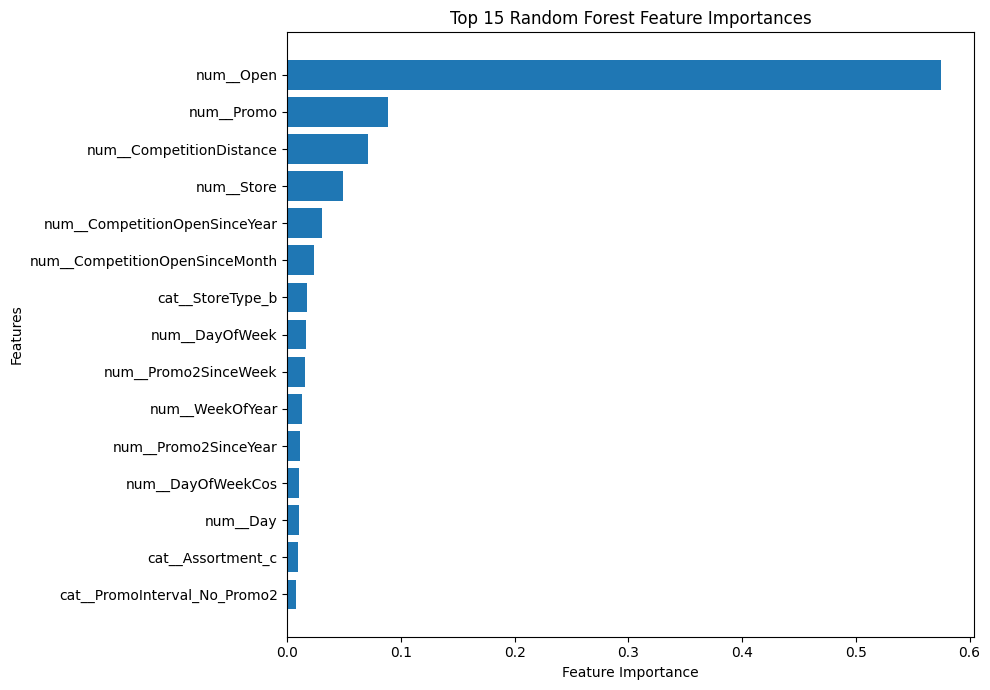

In [28]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Random Forest Feature Importances")

plt.tight_layout()
plt.show()

### Random Forest Feature Importance Analysis

The feature importance analysis shows that `Open` is the most influential feature in predicting store sales, contributing approximately 57.52% of the total importance. This is expected because store operating status has a strong relationship with sales.

`Promo` is the second most important feature (8.85%), followed by `CompetitionDistance` (7.09%). Store identity and competition opening dates also contribute to the model's predictions.

These findings suggest that store operating status, promotional activities, and competitive conditions are important predictors of Rossmann store sales. However, feature importance indicates predictive usefulness rather than a causal relationship.

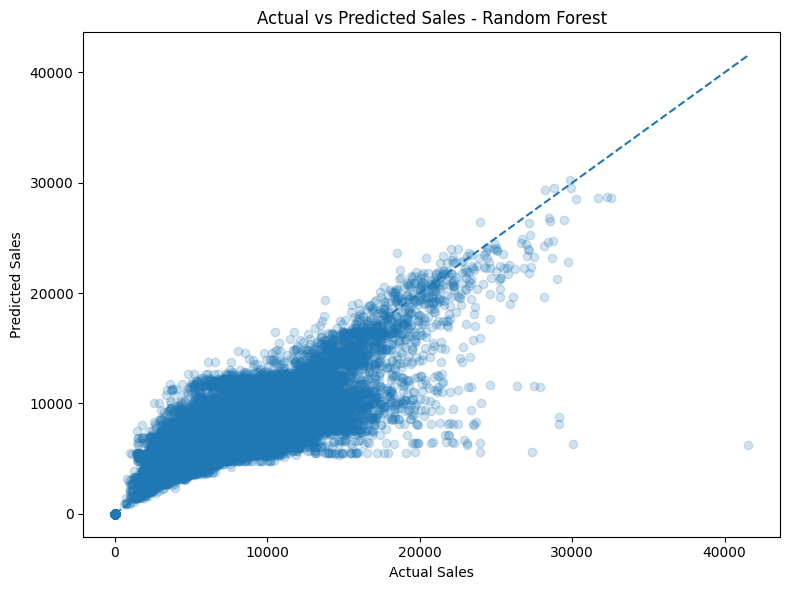

In [29]:
plt.figure(figsize=(8, 6))

plt.scatter(y_valid, y_pred, alpha=0.2)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales - Random Forest")

plt.plot(
    [0, y_valid.max()],
    [0, y_valid.max()],
    linestyle="--"
)

plt.tight_layout()
plt.show()

### Actual vs Predicted Sales Analysis

The Actual vs Predicted Sales scatter plot illustrates the predictive performance of the Random Forest Regressor. The dashed diagonal line represents perfect agreement between actual and predicted sales.

Many observations are concentrated around the diagonal, indicating that the model captures general sales patterns reasonably well. However, prediction errors become more noticeable at higher sales values. In particular, the model tends to underestimate some observations with exceptionally high sales.

Overall, the model provides a reasonable baseline, but its accuracy can be improved, especially for stores experiencing unusually high sales.

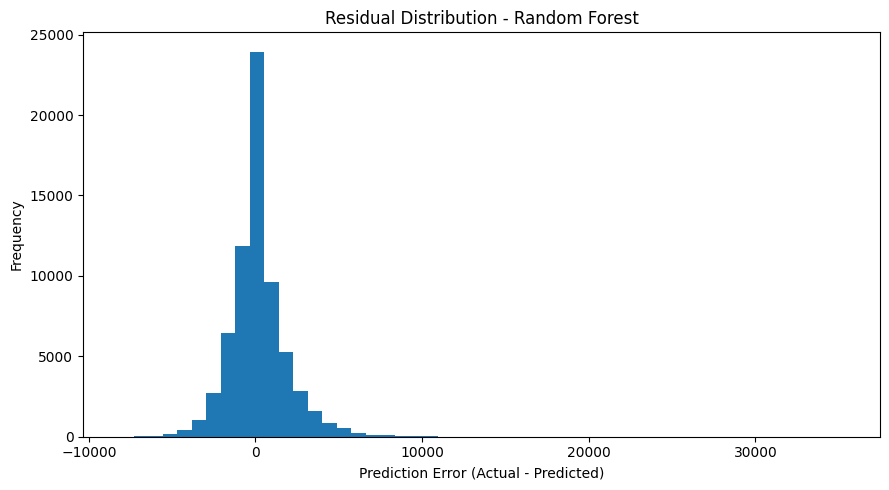

In [30]:
residuals = y_valid - y_pred

plt.figure(figsize=(9, 5))

plt.hist(residuals, bins=50)

plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Random Forest")

plt.tight_layout()
plt.show()

### Residual Distribution Analysis

The residual distribution is concentrated around zero, indicating that the Random Forest model does not have a large systematic error for most observations. However, the distribution is positively skewed, with a noticeable right tail. This indicates that the model tends to underestimate sales for some observations, particularly those with unusually high actual sales.

The residual analysis is consistent with the Actual vs Predicted plot, which also showed larger prediction errors for high-sales observations. Therefore, although the Random Forest provides a reasonable baseline, further model improvement may be beneficial for accurately predicting high-sales cases.

* Improving the model

In [31]:
rf_pipeline_v2 = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=30,
            max_depth=20,
            min_samples_split=5,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=1
        ))
    ]
)


In [32]:
import time
import gc

gc.collect()

start_time = time.time()

rf_pipeline_v2.fit(X_train, y_train)

end_time = time.time()

print("Improved Random Forest training completed!")
print("Training time:", round(end_time - start_time, 2), "seconds")

Improved Random Forest training completed!
Training time: 202.82 seconds


In [33]:
y_pred_v2 = rf_pipeline_v2.predict(X_valid)

print("V2 predictions generated successfully!")
print("Number of predictions:", len(y_pred_v2))
print("First 10 predictions:", y_pred_v2[:10])

V2 predictions generated successfully!
Number of predictions: 68015
First 10 predictions: [ 6058.9448415   7486.16291378 10137.55604164 13053.61775271
  7792.67470821  7726.86467594 12819.22023169  9143.8825888
 10272.0061829   7615.60715429]


In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# MAE
mae_v2 = mean_absolute_error(y_valid, y_pred_v2)

# RMSE
rmse_v2 = np.sqrt(mean_squared_error(y_valid, y_pred_v2))

# RMSPE (excluding zero actual sales)
mask = y_valid > 0

rmspe_v2 = np.sqrt(
    np.mean(
        ((y_valid[mask] - y_pred_v2[mask]) / y_valid[mask]) ** 2
    )
)

print("Random Forest V2 Evaluation Results")
print("-----------------------------------")
print("MAE   :", round(mae_v2, 2))
print("RMSE  :", round(rmse_v2, 2))
print("RMSPE :", round(rmspe_v2, 4))

Random Forest V2 Evaluation Results
-----------------------------------
MAE   : 834.17
RMSE  : 1312.75
RMSPE : 0.2103


In [36]:
residuals_v2 = y_valid - y_pred_v2

print("Residual Statistics")
print("-------------------")
print("Mean:", round(residuals_v2.mean(), 2))
print("Standard Deviation:", round(residuals_v2.std(), 2))
print("Minimum:", round(residuals_v2.min(), 2))
print("Maximum:", round(residuals_v2.max(), 2))

Residual Statistics
-------------------
Mean: 97.15
Standard Deviation: 1309.16
Minimum: -8563.17
Maximum: 34212.22


In [37]:
lower_error = np.percentile(residuals_v2, 2.5)
upper_error = np.percentile(residuals_v2, 97.5)

print("95% Empirical Prediction Error Interval")
print("----------------------------------------")
print("Lower error:", round(lower_error, 2))
print("Upper error:", round(upper_error, 2))

95% Empirical Prediction Error Interval
----------------------------------------
Lower error: -2373.13
Upper error: 3081.3


In [38]:
lower_bound = y_pred_v2 + lower_error
upper_bound = y_pred_v2 + upper_error

covered = (
    (y_valid >= lower_bound) &
    (y_valid <= upper_bound)
)

coverage = covered.mean() * 100

print("Prediction Interval Coverage:", round(coverage, 2), "%")
print("Observations inside interval:", covered.sum())
print("Total observations:", len(y_valid))

Prediction Interval Coverage: 95.0 %
Observations inside interval: 64613
Total observations: 68015


### Prediction Interval and Uncertainty Analysis

To estimate the uncertainty of the Random Forest V2 predictions, an empirical 95% prediction interval was constructed using the 2.5th and 97.5th percentiles of the validation residuals.

The lower residual bound was -2,373.13, while the upper residual bound was +3,081.30. These bounds were added to individual predicted sales values to obtain lower and upper prediction estimates.

The resulting interval covered 64,613 out of 68,015 validation observations, achieving an empirical coverage of 95.00%.

This analysis provides an estimate of prediction uncertainty and demonstrates how prediction intervals can communicate the expected range of sales. However, the interval is based on validation residuals and does not guarantee 95% coverage on future unseen data.

* Serialization

In [39]:
import pickle

# Serialize the trained Random Forest V2 pipeline
with open("random_forest_model_v2.pkl", "wb") as file:
    pickle.dump(rf_pipeline_v2, file)

print("Random Forest V2 serialized successfully using pickle!")

Random Forest V2 serialized successfully using pickle!


* Deserialization

In [40]:
import pickle

# Deserialize the saved Random Forest V2 model
with open("random_forest_model_v2.pkl", "rb") as file:
    loaded_rf_pipeline_v2 = pickle.load(file)

print("Random Forest V2 deserialized successfully!")

Random Forest V2 deserialized successfully!


In [42]:
from google.colab import files

files.download("random_forest_model_v2.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
import numpy as np

# Generate predictions using the deserialized model
y_pred_loaded = loaded_rf_pipeline_v2.predict(X_valid)

# Compare with original V2 predictions
same_predictions = np.allclose(y_pred_v2, y_pred_loaded)

print("Predictions match:", same_predictions)

Predictions match: True
